# Notebook 03: Huấn luyện mô hình, Tinh chỉnh siêu tham số & Ensemble (Modeling & Tuning)

**Đề tài:** Dự đoán hủy đặt phòng khách sạn tại thời điểm xác nhận đặt phòng (Strict Booking Confirmation)  
**Đầu vào:** `processed/hotel_clean.csv`  
**Đầu ra mô hình (`model/` — chỉ chứa `.joblib`):** `lgbm.joblib`, `xgb.joblib`, `catboost.joblib`, `ensemble.joblib`, `best_model.joblib`  
**Đầu ra siêu dữ liệu & kết quả thí nghiệm (`artifacts/`):** `split_metadata.json`, `experiment_metrics.csv`  
*(Biểu đồ trong Notebook 03 hiển thị trực tiếp inline, không xuất file PNG).*

### Kiến trúc phương pháp luận
1. **Chia dữ liệu 3 phần theo nhóm (`StratifiedGroupKFold` 2 giai đoạn)**:
   - **Train (~64%)**: Dùng cho 5-fold `StratifiedGroupKFold` CV và `RandomizedSearchCV`.
   - **Validation (~16%)**: Dùng cho lựa chọn mô hình (cá lẻ vs. ensemble) và (ở Notebook 04) tinh chỉnh ngưỡng quyết định.
   - **Test (~20%)**: **Hoàn toàn không đụng tới trong Notebook 03** — chỉ mở khóa một lần duy nhất ở Notebook 04.
2. **Tiền xử lý đặc thù từng họ mô hình**:
   - `LogisticRegression`, `RandomForest`, `XGBoost`, `LightGBM`: `OneHotEncoder(handle_unknown='ignore', min_frequency=0.005, sparse_output=True, dtype=np.float32)` (không dùng `OrdinalEncoder` cho biến định danh).
   - `CatBoost`: Pipeline riêng dùng `ColumnTransformer(..., verbose_feature_names_out=False).set_output(transform='pandas')` với `cat_features` bản địa.
3. **Thước đo chính**: `average_precision` (PR-AUC) là thước đo chính tối ưu phát hiện hủy phòng; `ROC-AUC` là thước đo phụ; tách bạch rõ thước đo độc lập ngưỡng và phụ thuộc ngưỡng.
4. **Ensemble nhận biết nhóm nội bộ**: So sánh `VotingClassifier(voting='soft')` và `StackingClassifier` (truyền sẵn `internal_cv = list(StratifiedGroupKFold(...).split(...))` và kiểm chứng 0 chồng lấn `group_id` ở mọi fold nội bộ).
5. **Lưu đúng đối tượng mô hình đã đánh giá**: Không refit lại sau khi đánh giá; kiểm chứng `np.allclose` sau khi tải lại `best_model.joblib`.

In [1]:
from pathlib import Path
import json
import sys
import time
import warnings
warnings.filterwarnings('ignore')

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, VotingClassifier, StackingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, roc_auc_score, log_loss,
    f1_score, precision_score, recall_score
)
from sklearn.model_selection import StratifiedGroupKFold, RandomizedSearchCV, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

import lightgbm as lgb
from lightgbm import LGBMClassifier
import xgboost as xgb
from xgboost import XGBClassifier
import catboost
from catboost import CatBoostClassifier

SEED = 42
np.random.seed(SEED)
sns.set_theme(style='whitegrid')

DATA_PATH = Path('processed/hotel_clean.csv')
MODEL_DIR = Path('model')
ARTIFACT_DIR = Path('artifacts')
MODEL_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

PACKAGE_VERSIONS = {
    'python': sys.version.split()[0],
    'numpy': np.__version__,
    'pandas': pd.__version__,
    'scikit-learn': sklearn.__version__,
    'lightgbm': lgb.__version__,
    'xgboost': xgb.__version__,
    'catboost': catboost.__version__,
}
print('Phiên bản thư viện:', json.dumps(PACKAGE_VERSIONS, indent=2))

df = pd.read_csv(DATA_PATH)
TARGET_COL = 'is_canceled'
METADATA_COLS = [
    'row_id', 'group_id', 'arrival_date', 'booking_date', 'arrival_date_year',
    'adr', 'estimated_booking_value_proxy', 'is_extreme_adr'
]
MODEL_FEATURES = [c for c in df.columns if c not in METADATA_COLS and c != TARGET_COL]

# Kiểm tra chắc chắn không có cột metadata/leakage trong MODEL_FEATURES
FORBIDDEN = {
    'is_canceled', 'row_id', 'group_id', 'arrival_date', 'booking_date', 'arrival_date_year',
    'reservation_status', 'reservation_status_date', 'assigned_room_type', 'booking_changes',
    'adr', 'adr_per_person', 'estimated_booking_value_proxy', 'is_extreme_adr', 'company'
}
assert FORBIDDEN.isdisjoint(set(MODEL_FEATURES)), f'Cột cấm trong MODEL_FEATURES: {FORBIDDEN & set(MODEL_FEATURES)}'

num_cols = [c for c in MODEL_FEATURES if pd.api.types.is_numeric_dtype(df[c])]
cat_cols = [c for c in MODEL_FEATURES if c not in num_cols]
for c in cat_cols:
    df[c] = df[c].astype(str)

print(f'Dữ liệu sạch: {df.shape[0]:,} dòng | MODEL_FEATURES: {len(MODEL_FEATURES)} ({len(num_cols)} số, {len(cat_cols)} phân loại)')
print('Biến phân loại:', cat_cols)

Phiên bản thư viện: {
  "python": "3.11.17",
  "numpy": "2.4.6",
  "pandas": "3.1.0",
  "scikit-learn": "1.9.1",
  "lightgbm": "4.7.0",
  "xgboost": "3.2.0",
  "catboost": "1.2.10"
}
Dữ liệu sạch: 119,209 dòng | MODEL_FEATURES: 41 (31 số, 10 phân loại)
Biến phân loại: ['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'deposit_type', 'agent', 'customer_type']


## 1. Chia tập Train (~64%) / Validation (~16%) / Test (~20%) bằng `StratifiedGroupKFold`

Do chia theo nhóm (`group_id`), tỷ lệ thực tế có thể dao động nhẹ quanh 64/16/20. Ta đo lường và báo cáo chính xác kích thước, tỷ lệ phần trăm, số nhóm duy nhất, tỷ lệ hủy phòng và kiểm chứng **0 chồng lấn `group_id`** giữa cả 3 tập.

In [2]:
X_all = df[MODEL_FEATURES].copy()
y_all = df[TARGET_COL].astype(int).copy()
groups_all = df['group_id'].astype(int).copy()

# Giai đoạn 1: Tách Test (~20%) khỏi TrainVal (~80%)
sgkf_outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
trainval_pos, test_pos = next(sgkf_outer.split(X_all, y_all, groups_all))

# Giai đoạn 2: Tách Validation (~16%) khỏi Train (~64%) trên TrainVal
sgkf_val = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
rel_train_pos, rel_val_pos = next(
    sgkf_val.split(X_all.iloc[trainval_pos], y_all.iloc[trainval_pos], groups_all.iloc[trainval_pos])
)
train_pos = trainval_pos[rel_train_pos]
val_pos = trainval_pos[rel_val_pos]

X_train, y_train, g_train = X_all.iloc[train_pos].reset_index(drop=True), y_all.iloc[train_pos].reset_index(drop=True), groups_all.iloc[train_pos].reset_index(drop=True)
X_val, y_val, g_val = X_all.iloc[val_pos].reset_index(drop=True), y_all.iloc[val_pos].reset_index(drop=True), groups_all.iloc[val_pos].reset_index(drop=True)
X_test, y_test, g_test = X_all.iloc[test_pos].reset_index(drop=True), y_all.iloc[test_pos].reset_index(drop=True), groups_all.iloc[test_pos].reset_index(drop=True)

# Kiểm chứng 0 chồng lấn group_id giữa 3 tập
set_tr, set_va, set_te = set(g_train), set(g_val), set(g_test)
assert set_tr.isdisjoint(set_va), 'Rò rỉ group_id giữa Train và Validation!'
assert set_tr.isdisjoint(set_te), 'Rò rỉ group_id giữa Train và Test!'
assert set_va.isdisjoint(set_te), 'Rò rỉ group_id giữa Validation và Test!'

split_summary = pd.DataFrame([
    {'Tập dữ liệu': 'Train', 'Số dòng': len(X_train), 'Tỷ lệ thực (%)': round(len(X_train)/len(df)*100, 2),
     'Số group_id duy nhất': len(set_tr), 'Tỷ lệ hủy (%)': round(y_train.mean()*100, 2)},
    {'Tập dữ liệu': 'Validation', 'Số dòng': len(X_val), 'Tỷ lệ thực (%)': round(len(X_val)/len(df)*100, 2),
     'Số group_id duy nhất': len(set_va), 'Tỷ lệ hủy (%)': round(y_val.mean()*100, 2)},
    {'Tập dữ liệu': 'Test (Untouched)', 'Số dòng': len(X_test), 'Tỷ lệ thực (%)': round(len(X_test)/len(df)*100, 2),
     'Số group_id duy nhất': len(set_te), 'Tỷ lệ hủy (%)': round(y_test.mean()*100, 2)},
])
display(split_summary)
print('Kiểm chứng Zero Group Overlap (Train / Val / Test): ĐẠT 100%')

# Lưu split_metadata.json vào artifacts/ (bên ngoài model/)
split_metadata = {
    'random_seed': SEED,
    'strategy': 'Two-stage StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)',
    'total_rows': int(len(df)),
    'total_unique_groups': int(groups_all.nunique()),
    'splits': {
        'train': {'n_rows': int(len(X_train)), 'pct': round(len(X_train)/len(df)*100, 3),
                  'n_groups': int(len(set_tr)), 'cancel_rate': round(float(y_train.mean()), 5)},
        'validation': {'n_rows': int(len(X_val)), 'pct': round(len(X_val)/len(df)*100, 3),
                       'n_groups': int(len(set_va)), 'cancel_rate': round(float(y_val.mean()), 5)},
        'test': {'n_rows': int(len(X_test)), 'pct': round(len(X_test)/len(df)*100, 3),
                 'n_groups': int(len(set_te)), 'cancel_rate': round(float(y_test.mean()), 5)},
    },
    'metadata_cols': METADATA_COLS,
    'model_features': MODEL_FEATURES,
    'num_cols': num_cols,
    'cat_cols': cat_cols,
    'package_versions': PACKAGE_VERSIONS,
}
(ARTIFACT_DIR / 'split_metadata.json').write_text(json.dumps(split_metadata, indent=2, ensure_ascii=False), encoding='utf-8')
print('Đã lưu: artifacts/split_metadata.json')

Kiểm chứng Zero Group Overlap (Train / Val / Test): ĐẠT 100%
Đã lưu: artifacts/split_metadata.json


,Tập dữ liệu,Số dòng,Tỷ lệ thực (%),Số group_id duy nhất,Tỷ lệ hủy (%)
0,Train,76229,63.95,53443,37.07
1,Validation,19058,15.99,13398,37.07
2,Test (Untouched),23922,20.07,16695,37.12


## 2. Xây dựng Pipeline Tiền xử lý & So sánh mô hình cơ sở (5-fold `StratifiedGroupKFold` trên Train)

- **Pipeline Sparse `float32` OneHotEncoder**: dùng cho `LogisticRegression` (kèm `StandardScaler(with_mean=False)`), `RandomForest`, `XGBoost`, và `LightGBM`.
- **Pipeline CatBoost bản địa**: `ColumnTransformer(..., verbose_feature_names_out=False).set_output(transform='pandas')`, truyền trực tiếp `cat_features=cat_cols` cho `CatBoostClassifier`.
- Mọi chỉ số CV được tính **hoàn toàn bên trong tập Train (~64%)**.

Dummy (Most Frequent)    | PR-AUC: 0.3707 +/- 0.0000 | ROC-AUC: 0.5000 | F1@0.50: 0.0000 | 12.0s
Logistic Regression      | PR-AUC: 0.8633 +/- 0.0096 | ROC-AUC: 0.9013 | F1@0.50: 0.7372 | 22.7s
Random Forest            | PR-AUC: 0.9024 +/- 0.0040 | ROC-AUC: 0.9324 | F1@0.50: 0.7796 | 20.0s
XGBoost (Baseline)       | PR-AUC: 0.9044 +/- 0.0043 | ROC-AUC: 0.9340 | F1@0.50: 0.7948 | 14.7s
LightGBM (Baseline)      | PR-AUC: 0.9061 +/- 0.0041 | ROC-AUC: 0.9353 | F1@0.50: 0.7993 | 13.4s
CatBoost (Baseline)      | PR-AUC: 0.9063 +/- 0.0039 | ROC-AUC: 0.9353 | F1@0.50: 0.7948 | 75.4s


,stage,model,pr_auc_mean,pr_auc_std,roc_auc_mean,roc_auc_std,logloss_mean,f1_at_050,precision_at_050,recall_at_050,fit_time_sec
0,CV_Baseline_Train,CatBoost (Baseline),0.9063,0.0039,0.9353,0.0029,0.3024,0.7948,0.8301,0.7625,75.43
1,CV_Baseline_Train,LightGBM (Baseline),0.9061,0.0041,0.9353,0.0033,0.3024,0.7993,0.8350,0.7665,13.35
2,CV_Baseline_Train,XGBoost (Baseline),0.9044,0.0043,0.9340,0.0034,0.3060,0.7948,0.8350,0.7584,14.69
3,CV_Baseline_Train,Random Forest,0.9024,0.0040,0.9324,0.0031,0.3227,0.7796,0.8577,0.7146,20.02
4,CV_Baseline_Train,Logistic Regression,0.8633,0.0096,0.9013,0.0085,0.3675,0.7372,0.8026,0.6817,22.71
5,CV_Baseline_Train,Dummy (Most Frequent),0.3707,0.0000,0.5000,0.0000,13.3599,0.0000,0.0000,0.0000,11.98


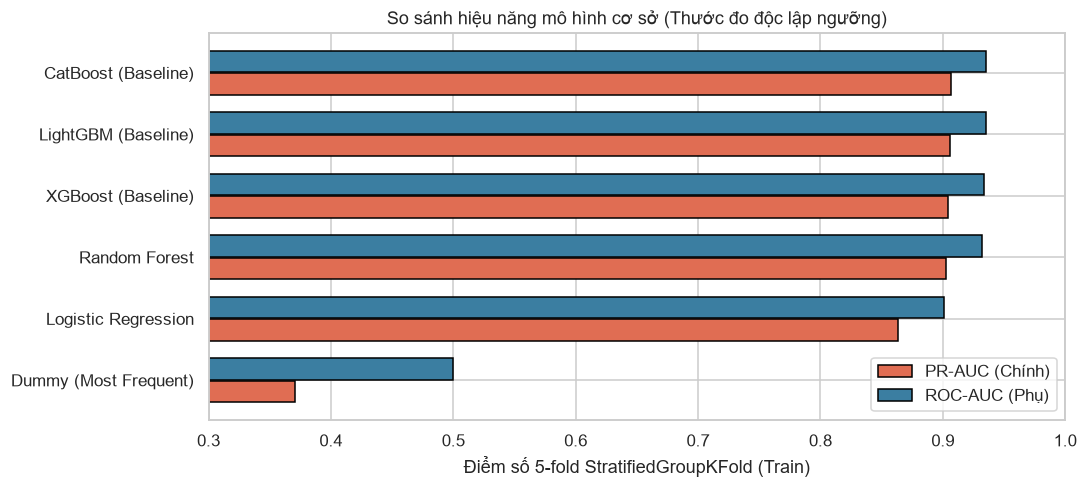

In [3]:
def make_ohe_preprocessor(scale_numeric: bool = False) -> ColumnTransformer:
    num_steps = [('imputer', SimpleImputer(strategy='median'))]
    if scale_numeric:
        num_steps.append(('scaler', StandardScaler(with_mean=False)))
    cat_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('ohe', OneHotEncoder(handle_unknown='ignore', min_frequency=0.005, sparse_output=True, dtype=np.float32)),
    ])
    return ColumnTransformer(
        transformers=[
            ('num', Pipeline(num_steps), num_cols),
            ('cat', cat_pipe, cat_cols),
        ],
        sparse_threshold=0.3,
    )

def make_catboost_preprocessor() -> ColumnTransformer:
    ct = ColumnTransformer(
        transformers=[
            ('num', SimpleImputer(strategy='median'), num_cols),
            ('cat', SimpleImputer(strategy='constant', fill_value='Missing'), cat_cols),
        ],
        verbose_feature_names_out=False,
    )
    ct.set_output(transform='pandas')
    return ct

cv_train = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)

baseline_models = {
    'Dummy (Most Frequent)': Pipeline([
        ('prep', make_ohe_preprocessor(False)),
        ('clf', DummyClassifier(strategy='most_frequent'))
    ]),
    'Logistic Regression': Pipeline([
        ('prep', make_ohe_preprocessor(True)),
        ('clf', LogisticRegression(max_iter=1000, C=1.0, random_state=SEED))
    ]),
    'Random Forest': Pipeline([
        ('prep', make_ohe_preprocessor(False)),
        ('clf', RandomForestClassifier(n_estimators=200, max_depth=18, min_samples_leaf=5, n_jobs=-1, random_state=SEED))
    ]),
    'XGBoost (Baseline)': Pipeline([
        ('prep', make_ohe_preprocessor(False)),
        ('clf', XGBClassifier(
            n_estimators=300, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8,
            eval_metric='logloss', tree_method='hist', n_jobs=-1, random_state=SEED
        ))
    ]),
    'LightGBM (Baseline)': Pipeline([
        ('prep', make_ohe_preprocessor(False)),
        ('clf', LGBMClassifier(
            n_estimators=300, learning_rate=0.05, num_leaves=31, subsample=0.8, colsample_bytree=0.8,
            n_jobs=-1, random_state=SEED, verbose=-1
        ))
    ]),
    'CatBoost (Baseline)': Pipeline([
        ('prep', make_catboost_preprocessor()),
        ('clf', CatBoostClassifier(
            iterations=400, learning_rate=0.06, depth=6, cat_features=tuple(cat_cols),
            random_seed=SEED, verbose=0, thread_count=-1
        ))
    ]),
}

scoring = {
    'pr_auc': 'average_precision',
    'roc_auc': 'roc_auc',
    'neg_log_loss': 'neg_log_loss',
    'f1': 'f1',
    'precision': 'precision',
    'recall': 'recall',
}

cv_rows = []
for name, pipe in baseline_models.items():
    t0 = time.perf_counter()
    res = cross_validate(pipe, X_train, y_train, groups=g_train, cv=cv_train, scoring=scoring, n_jobs=1)
    elapsed = time.perf_counter() - t0
    cv_rows.append({
        'stage': 'CV_Baseline_Train',
        'model': name,
        'pr_auc_mean': round(float(res['test_pr_auc'].mean()), 4),
        'pr_auc_std': round(float(res['test_pr_auc'].std()), 4),
        'roc_auc_mean': round(float(res['test_roc_auc'].mean()), 4),
        'roc_auc_std': round(float(res['test_roc_auc'].std()), 4),
        'logloss_mean': round(float(-res['test_neg_log_loss'].mean()), 4),
        'f1_at_050': round(float(res['test_f1'].mean()), 4),
        'precision_at_050': round(float(res['test_precision'].mean()), 4),
        'recall_at_050': round(float(res['test_recall'].mean()), 4),
        'fit_time_sec': round(elapsed, 2),
    })
    print(f'{name:24s} | PR-AUC: {cv_rows[-1]["pr_auc_mean"]:.4f} +/- {cv_rows[-1]["pr_auc_std"]:.4f} | ROC-AUC: {cv_rows[-1]["roc_auc_mean"]:.4f} | F1@0.50: {cv_rows[-1]["f1_at_050"]:.4f} | {elapsed:.1f}s')

cv_df = pd.DataFrame(cv_rows).sort_values('pr_auc_mean', ascending=False).reset_index(drop=True)
display(cv_df)

# Biểu đồ inline so sánh PR-AUC & ROC-AUC (không xuất PNG)
fig, ax = plt.subplots(figsize=(10, 4.6))
plot_df = cv_df.sort_values('pr_auc_mean', ascending=True)
y_pos = np.arange(len(plot_df))
ax.barh(y_pos - 0.18, plot_df['pr_auc_mean'], height=0.35, label='PR-AUC (Chính)', color='#E06D53', edgecolor='black')
ax.barh(y_pos + 0.18, plot_df['roc_auc_mean'], height=0.35, label='ROC-AUC (Phụ)', color='#3B7EA1', edgecolor='black')
ax.set_yticks(y_pos)
ax.set_yticklabels(plot_df['model'])
ax.set_xlabel('Điểm số 5-fold StratifiedGroupKFold (Train)')
ax.set_title('So sánh hiệu năng mô hình cơ sở (Thước đo độc lập ngưỡng)')
ax.set_xlim(0.3, 1.0)
ax.legend()
plt.tight_layout()
plt.show()

## 3. Tinh chỉnh siêu tham số (`RandomizedSearchCV` trên Train) & Kiểm tra độ nhạy Cutoff

- Sử dụng `RandomizedSearchCV` với `cv = StratifiedGroupKFold(n_splits=5)` và `scoring = 'average_precision'` (PR-AUC) **chỉ trên tập Train (~64%)**.
- Ngoài ra, thực hiện **Kiểm tra độ nhạy Cutoff trên Validation** với `deposit_type` và `country` (các biến đã được đánh dấu cần thận trọng ở Notebook 01) để báo cáo định lượng mức độ ảnh hưởng của chúng.

In [4]:
# 3.1 Tuning LightGBM
lgbm_search = RandomizedSearchCV(
    estimator=Pipeline([
        ('prep', make_ohe_preprocessor(False)),
        ('clf', LGBMClassifier(n_jobs=-1, random_state=SEED, verbose=-1))
    ]),
    param_distributions={
        'clf__n_estimators': [300, 500, 700],
        'clf__learning_rate': [0.03, 0.05, 0.08],
        'clf__num_leaves': [31, 63, 95],
        'clf__min_child_samples': [20, 40, 80],
        'clf__subsample': [0.75, 0.85, 1.0],
        'clf__colsample_bytree': [0.7, 0.85, 1.0],
        'clf__reg_alpha': [0.0, 0.5, 2.0],
        'clf__reg_lambda': [0.0, 1.0, 5.0],
    },
    n_iter=12,
    scoring='average_precision',
    cv=cv_train,
    random_state=SEED,
    n_jobs=1,
    refit=True,
)
t0 = time.perf_counter()
lgbm_search.fit(X_train, y_train, groups=g_train)
print(f'[LightGBM Tuned] Best CV PR-AUC: {lgbm_search.best_score_:.4f} ({time.perf_counter()-t0:.1f}s)')
print('  Best params:', lgbm_search.best_params_)
lgbm_best = lgbm_search.best_estimator_

# 3.2 Tuning XGBoost
xgb_search = RandomizedSearchCV(
    estimator=Pipeline([
        ('prep', make_ohe_preprocessor(False)),
        ('clf', XGBClassifier(eval_metric='logloss', tree_method='hist', n_jobs=-1, random_state=SEED))
    ]),
    param_distributions={
        'clf__n_estimators': [300, 500, 700],
        'clf__learning_rate': [0.03, 0.05, 0.08],
        'clf__max_depth': [5, 7, 9],
        'clf__min_child_weight': [1, 5, 15],
        'clf__subsample': [0.75, 0.85, 1.0],
        'clf__colsample_bytree': [0.7, 0.85, 1.0],
        'clf__reg_lambda': [1.0, 3.0, 10.0],
    },
    n_iter=12,
    scoring='average_precision',
    cv=cv_train,
    random_state=SEED,
    n_jobs=1,
    refit=True,
)
t0 = time.perf_counter()
xgb_search.fit(X_train, y_train, groups=g_train)
print(f'[XGBoost Tuned]  Best CV PR-AUC: {xgb_search.best_score_:.4f} ({time.perf_counter()-t0:.1f}s)')
print('  Best params:', xgb_search.best_params_)
xgb_best = xgb_search.best_estimator_

# 3.3 Tuning CatBoost (Native Categoricals)
cb_search = RandomizedSearchCV(
    estimator=Pipeline([
        ('prep', make_catboost_preprocessor()),
        ('clf', CatBoostClassifier(cat_features=tuple(cat_cols), random_seed=SEED, verbose=0, thread_count=-1))
    ]),
    param_distributions={
        'clf__iterations': [400, 600, 800],
        'clf__learning_rate': [0.04, 0.06, 0.09],
        'clf__depth': [5, 6, 8],
        'clf__l2_leaf_reg': [3.0, 6.0, 10.0],
    },
    n_iter=8,
    scoring='average_precision',
    cv=cv_train,
    random_state=SEED,
    n_jobs=1,
    refit=True,
)
t0 = time.perf_counter()
cb_search.fit(X_train, y_train, groups=g_train)
print(f'[CatBoost Tuned] Best CV PR-AUC: {cb_search.best_score_:.4f} ({time.perf_counter()-t0:.1f}s)')
print('  Best params:', cb_search.best_params_)
catboost_best = cb_search.best_estimator_

[LightGBM Tuned] Best CV PR-AUC: 0.9101 (144.6s)
  Best params: {'clf__subsample': 0.85, 'clf__reg_lambda': 5.0, 'clf__reg_alpha': 0.0, 'clf__num_leaves': 95, 'clf__n_estimators': 700, 'clf__min_child_samples': 40, 'clf__learning_rate': 0.03, 'clf__colsample_bytree': 0.7}
[XGBoost Tuned]  Best CV PR-AUC: 0.9103 (156.7s)
  Best params: {'clf__subsample': 0.75, 'clf__reg_lambda': 1.0, 'clf__n_estimators': 700, 'clf__min_child_weight': 1, 'clf__max_depth': 9, 'clf__learning_rate': 0.03, 'clf__colsample_bytree': 1.0}
[CatBoost Tuned] Best CV PR-AUC: 0.9087 (769.3s)
  Best params: {'clf__learning_rate': 0.06, 'clf__l2_leaf_reg': 10.0, 'clf__iterations': 600, 'clf__depth': 8}


In [5]:
# 3.4 Kiểm tra độ nhạy Cutoff trên Validation (deposit_type & country)
def eval_subset_val(drop_list, label):
    sub_feats = [c for c in MODEL_FEATURES if c not in drop_list]
    sub_num = [c for c in sub_feats if c in num_cols]
    sub_cat = [c for c in sub_feats if c in cat_cols]
    prep = ColumnTransformer([
        ('num', SimpleImputer(strategy='median'), sub_num),
        ('cat', Pipeline([
            ('imp', SimpleImputer(strategy='most_frequent')),
            ('ohe', OneHotEncoder(handle_unknown='ignore', min_frequency=0.005, sparse_output=True, dtype=np.float32))
        ]), sub_cat)
    ], sparse_threshold=0.3)
    clf = clone(lgbm_best.named_steps['clf'])
    pipe = Pipeline([('prep', prep), ('clf', clf)])
    pipe.fit(X_train[sub_feats], y_train)
    p = pipe.predict_proba(X_val[sub_feats])[:, 1]
    return {
        'Kịch bản Cutoff (Validation)': label,
        'Số đặc trưng': len(sub_feats),
        'Val PR-AUC': round(average_precision_score(y_val, p), 4),
        'Val ROC-AUC': round(roc_auc_score(y_val, p), 4),
    }

sens_rows = [
    eval_subset_val([], 'Strict Booking-Time (Đầy đủ MODEL_FEATURES)'),
    eval_subset_val(['country', 'is_portugal'], 'Loại country & is_portugal (tránh thiên lệch hộ chiếu check-in)'),
    eval_subset_val(['deposit_type'], 'Loại deposit_type (tránh bất thường Non Refund ~99.4%)'),
    eval_subset_val(['country', 'is_portugal', 'deposit_type'], 'Loại cả country & deposit_type (Ultra-Conservative)'),
]
sens_df = pd.DataFrame(sens_rows)
print('--- Kiểm tra độ nhạy Cutoff trên tập Validation (LightGBM Tuned) ---')
display(sens_df)

--- Kiểm tra độ nhạy Cutoff trên tập Validation (LightGBM Tuned) ---


,Kịch bản Cutoff (Validation),Số đặc trưng,Val PR-AUC,Val ROC-AUC
0,Strict Booking-Time (Đầy đủ MODEL_FEATURES),41,0.9083,0.9377
1,Loại country & is_portugal (tránh thiên lệch hộ chiếu check-in),39,0.8567,0.8852
2,Loại deposit_type (tránh bất thường Non Refund ~99.4%),40,0.9001,0.9326
3,Loại cả country & deposit_type (Ultra-Conservative),38,0.8394,0.8774


## 4. Ensemble nhận biết nhóm nội bộ & Lựa chọn mô hình trên Validation (~16%)

- **VotingClassifier (`voting='soft'`)**: Kết hợp xác suất dự đoán của 3 mô hình đã tinh chỉnh (`lgbm`, `xgb`, `catboost`).
- **StackingClassifier nhận biết nhóm nội bộ**: Tạo sẵn danh sách fold nội bộ `internal_cv = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(X_train, y_train, g_train))` và **kiểm chứng 0 chồng lấn `group_id`** trong từng fold nội bộ trước khi truyền vào `StackingClassifier(cv=internal_cv)`.
- So sánh toàn bộ 5 ứng viên (`lgbm`, `xgb`, `catboost`, `voting`, `stacking`) trên **Validation (~16%)** theo `PR-AUC` (chính) và `ROC-AUC` (phụ). **Không đụng vào Test!**

In [6]:
# 4.1 Tạo internal_cv cho Stacking và kiểm chứng Zero Group Overlap ở mọi fold nội bộ
internal_cv = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(X_train, y_train, g_train))
for fold_i, (tr_i, va_i) in enumerate(internal_cv):
    g_tr_fold = set(g_train.iloc[tr_i])
    g_va_fold = set(g_train.iloc[va_i])
    assert g_tr_fold.isdisjoint(g_va_fold), f'Rò rỉ group_id trong Stacking fold nội bộ #{fold_i}!'
print(f'Kiểm chứng Zero Group Overlap cho cả {len(internal_cv)} fold nội bộ của StackingClassifier: ĐẠT 100%')

# 4.2 Huấn luyện VotingClassifier (soft) trên Train
voting_clf = VotingClassifier(
    estimators=[
        ('lgbm', clone(lgbm_best)),
        ('xgb', clone(xgb_best)),
        ('catboost', clone(catboost_best)),
    ],
    voting='soft',
    n_jobs=1,
)
t0 = time.perf_counter()
voting_clf.fit(X_train, y_train)
print(f'[Voting Soft] Fit hoàn tất ({time.perf_counter()-t0:.1f}s)')

# 4.3 Huấn luyện StackingClassifier (group-aware internal_cv) trên Train
stacking_clf = StackingClassifier(
    estimators=[
        ('lgbm', clone(lgbm_best)),
        ('xgb', clone(xgb_best)),
        ('catboost', clone(catboost_best)),
    ],
    final_estimator=LogisticRegression(max_iter=1000, random_state=SEED),
    cv=internal_cv,
    stack_method='predict_proba',
    n_jobs=1,
)
t0 = time.perf_counter()
stacking_clf.fit(X_train, y_train)
print(f'[Stacking Group-Aware] Fit hoàn tất ({time.perf_counter()-t0:.1f}s)')

# 4.4 Đánh giá tất cả ứng viên trên Validation (~16%) — TUYỆT ĐỐI KHÔNG DÙNG TEST
candidates = {
    'lgbm': lgbm_best,
    'xgb': xgb_best,
    'catboost': catboost_best,
    'voting': voting_clf,
    'stacking': stacking_clf,
}

val_rows = []
val_probs = {}
for name, model in candidates.items():
    p_val = model.predict_proba(X_val)[:, 1]
    val_probs[name] = p_val
    y_hat_05 = (p_val >= 0.5).astype(int)
    val_rows.append({
        'stage': 'Validation_Selection',
        'model': name,
        'pr_auc_mean': round(float(average_precision_score(y_val, p_val)), 4),
        'pr_auc_std': np.nan,
        'roc_auc_mean': round(float(roc_auc_score(y_val, p_val)), 4),
        'roc_auc_std': np.nan,
        'logloss_mean': round(float(log_loss(y_val, p_val)), 4),
        'f1_at_050': round(float(f1_score(y_val, y_hat_05)), 4),
        'precision_at_050': round(float(precision_score(y_val, y_hat_05)), 4),
        'recall_at_050': round(float(recall_score(y_val, y_hat_05)), 4),
        'fit_time_sec': np.nan,
    })

val_df = pd.DataFrame(val_rows).sort_values('pr_auc_mean', ascending=False).reset_index(drop=True)
print('\n--- Kết quả lựa chọn mô hình trên tập Validation (~16%) ---')
display(val_df[['model', 'pr_auc_mean', 'roc_auc_mean', 'logloss_mean', 'f1_at_050', 'precision_at_050', 'recall_at_050']])

# Chọn ensemble tốt hơn (voting vs stacking) và best_model tổng thể theo Val PR-AUC
ens_winner_name = 'stacking' if val_df.set_index('model').loc['stacking', 'pr_auc_mean'] >= val_df.set_index('model').loc['voting', 'pr_auc_mean'] else 'voting'
ensemble_best = candidates[ens_winner_name]

best_model_name = str(val_df.iloc[0]['model'])
best_model_obj = candidates[best_model_name]
print(f'Ensemble thắng cuộc trên Validation: {ens_winner_name}')
print(f'Mô hình tốt nhất (best_model) trên Validation: {best_model_name} (Val PR-AUC = {val_df.iloc[0]["pr_auc_mean"]:.4f})')

Kiểm chứng Zero Group Overlap cho cả 5 fold nội bộ của StackingClassifier: ĐẠT 100%
[Voting Soft] Fit hoàn tất (38.0s)
[Stacking Group-Aware] Fit hoàn tất (207.7s)

--- Kết quả lựa chọn mô hình trên tập Validation (~16%) ---
Ensemble thắng cuộc trên Validation: stacking
Mô hình tốt nhất (best_model) trên Validation: stacking (Val PR-AUC = 0.9091)


,model,pr_auc_mean,roc_auc_mean,logloss_mean,f1_at_050,precision_at_050,recall_at_050
0,stacking,0.9091,0.9384,0.3157,0.8050,0.8392,0.7735
1,voting,0.9091,0.9383,0.2964,0.8033,0.8441,0.7663
2,lgbm,0.9083,0.9377,0.2975,0.8023,0.8407,0.7673
3,xgb,0.9062,0.9358,0.3020,0.8059,0.8424,0.7725
4,catboost,0.9061,0.9369,0.3004,0.7946,0.8396,0.7542


## 5. Lưu chính xác các đối tượng mô hình đã đánh giá (`model/*.joblib`) & Bảng thí nghiệm (`artifacts/`)

- `model/` **chỉ chứa đúng 5 file `.joblib`**: `lgbm.joblib`, `xgb.joblib`, `catboost.joblib`, `ensemble.joblib`, `best_model.joblib`.
- Không refit lại sau khi đánh giá — tải lại `best_model.joblib` và kiểm chứng `np.allclose` với xác suất dự đoán trên Validation để đảm bảo lưu chính xác 100% mô hình đã đánh giá.
- Lưu `artifacts/experiment_metrics.csv` (bên ngoài `model/`).

In [7]:
# Dọn sạch file lạ trong model/ nếu có (chỉ giữ .joblib)
for p in MODEL_DIR.iterdir():
    if p.is_file():
        p.unlink()

joblib.dump(lgbm_best, MODEL_DIR / 'lgbm.joblib')
joblib.dump(xgb_best, MODEL_DIR / 'xgb.joblib')
joblib.dump(catboost_best, MODEL_DIR / 'catboost.joblib')
joblib.dump(ensemble_best, MODEL_DIR / 'ensemble.joblib')
joblib.dump(best_model_obj, MODEL_DIR / 'best_model.joblib')

# Kiểm chứng tải lại best_model.joblib khớp tuyệt đối với mô hình trong bộ nhớ
reloaded_best = joblib.load(MODEL_DIR / 'best_model.joblib')
p_reloaded = reloaded_best.predict_proba(X_val)[:, 1]
assert np.allclose(p_reloaded, val_probs[best_model_name], atol=1e-7), 'Lỗi: best_model.joblib không khớp với mô hình đã đánh giá!'
print('Kiểm chứng tính toàn vẹn best_model.joblib (np.allclose): ĐẠT 100%')

# Lưu bảng kết quả thí nghiệm ra artifacts/experiment_metrics.csv
exp_df = pd.concat([cv_df, val_df], ignore_index=True)
exp_df['best_model_selected_on_val'] = best_model_name
exp_df['ensemble_winner_on_val'] = ens_winner_name
exp_df['random_seed'] = SEED
exp_df.to_csv(ARTIFACT_DIR / 'experiment_metrics.csv', index=False)

# Cập nhật thông tin chọn mô hình vào split_metadata.json
split_metadata['ensemble_winner_on_val'] = ens_winner_name
split_metadata['best_model_selected_on_val'] = best_model_name
(ARTIFACT_DIR / 'split_metadata.json').write_text(json.dumps(split_metadata, indent=2, ensure_ascii=False), encoding='utf-8')

print('\nCác file trong model/ (chỉ .joblib):')
for p in sorted(MODEL_DIR.iterdir()):
    print(f'  - {p.name} ({p.stat().st_size/1024:.1f} KB)')
print('Đã lưu: artifacts/experiment_metrics.csv')

Kiểm chứng tính toàn vẹn best_model.joblib (np.allclose): ĐẠT 100%

Các file trong model/ (chỉ .joblib):
  - best_model.joblib (22779.8 KB)
  - catboost.joblib (6301.4 KB)
  - ensemble.joblib (22779.8 KB)
  - lgbm.joblib (7172.2 KB)
  - xgb.joblib (6325.2 KB)
Đã lưu: artifacts/experiment_metrics.csv
